# UD08: Introducción al Machine Learning
## Caso Práctico: Predicción y Análisis de Datos

### **Curso:** Sistemas de Gestión Empresarial (SGE) - 2 DAMS
### **Autora:** Miriam  Mendieta.-
---


## Configuración y Carga de Datos

In [1]:
%%capture
#instalación de las librerías necesarias
%pip install -q pandas matplotlib seaborn numpy 

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


In [3]:
# Cargamos el dataset de Kaggle (previamente descargado)
df = pd.read_csv('ecommerce_data.csv', encoding='latin1')
 
# Inspeccionamos las primeras filas del dataset
df.head(5)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


## Limpieza de Datos

In [4]:
df.isnull().sum()
# Limpieza de datos: eliminar filas con valores nulos
df = df.dropna()

# Eliminamos filas sin ID de Cliente 
df_clean = df.dropna(subset=['CustomerID']).copy()

# Convertimos la columna InvoiceDate a tipo datetime
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])


print(f"Datos originales: {df.shape[0]}")
print(f"Datos tras limpieza: {df_clean.shape[0]}")

# Confirmación
df_clean.info()


Datos originales: 406829
Datos tras limpieza: 406829
<class 'pandas.DataFrame'>
Index: 406829 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    406829 non-null  str           
 1   StockCode    406829 non-null  str           
 2   Description  406829 non-null  str           
 3   Quantity     406829 non-null  int64         
 4   InvoiceDate  406829 non-null  datetime64[us]
 5   UnitPrice    406829 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      406829 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), str(4)
memory usage: 27.9 MB


## Análisis Exploratorio de Datos (EDA)

In [5]:
print(df.columns.tolist())

# Creamos la columna 'Sales' multiplicando cantidad por precio unitario
df['Sales'] = df['Quantity'] * df['UnitPrice']



['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


## Gráficas de distribución de ventas por mes


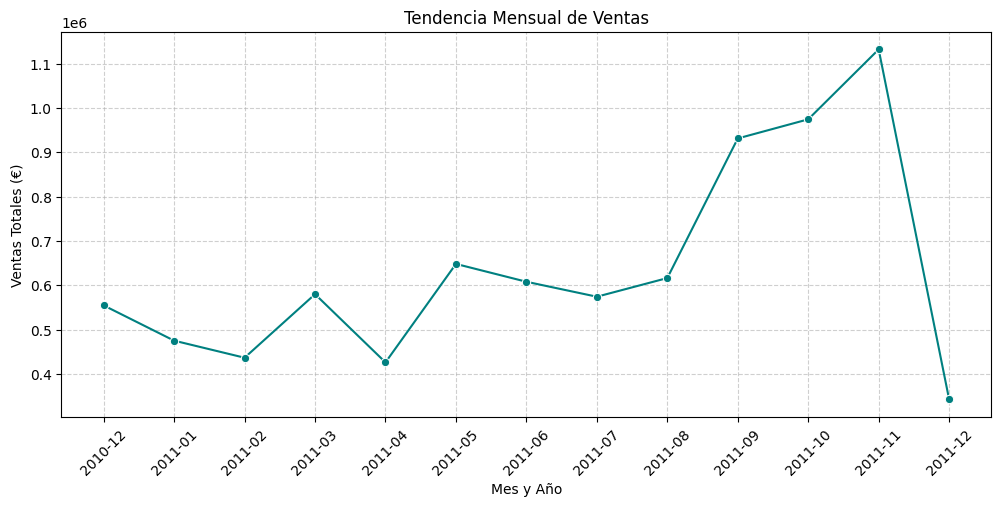

In [6]:
# Normalización de fechas: Convertimos el texto o formato original a objetos tipo datetime de Python
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Extracción de periodos: Creamos una representación de 'Año-Mes' (ej. '2023-01') para facilitar la agrupación
df['MonthYear'] = df['InvoiceDate'].dt.to_period('M').astype(str)

# agrupar por el nuevo periodo y sumamos la columna 'Sales' para obtener totales mensuales
monthly_sales = df.groupby('MonthYear')['Sales'].sum()

# Inicialización del lienzo: Definimos el ancho (12) y alto (5) de la figura del gráfico
plt.figure(figsize=(12, 5))

# Dibujo de la serie: Creamos el gráfico de líneas usando los índices (meses) y valores (ventas totales)
sns.lineplot(x=monthly_sales.index, y=monthly_sales.values, marker='o', color='teal')

# Títulos: Añadimos un título descriptivo a la parte superior del gráfico
plt.title('Tendencia Mensual de Ventas')

# Formato de etiquetas: Rotamos los nombres de los meses 45 grados para evitar que se solapen entre sí
plt.xticks(rotation=45)

# Etiquetas de ejes: Definimos los nombres de los ejes X (horizontal) e Y (vertical)
plt.xlabel('Mes y Año')
plt.ylabel('Ventas Totales (€)')

# Guías visuales: Añadimos una cuadrícula discontinua con opacidad del 60% para mejorar la lectura de datos
plt.grid(True, linestyle='--', alpha=0.6)

# Renderizado: Ordenamos a la librería que muestre el gráfico final en la interfaz
plt.show()

## Filtrado por año y preparación de la Predicción

In [7]:

# --- Filtrar por un año específico (ejemplo: 2011) ---
# Usamos .str.contains() porque 'MonthYear' es una cadena de texto
df_filtrado = df[df['MonthYear'].str.contains('2011')].copy()

# --- Agrupar datos filtrados ---
monthly_sales = df_filtrado.groupby('MonthYear')['Sales'].sum()

# ---  línea de tendencia (Predicción) ---
# índice numérico (0, 1, 2...) para representar los meses
x = np.arange(len(monthly_sales))
y = monthly_sales.values

# Calculamos los coeficientes de la recta: y = mx + b
# 
m, b = np.polyfit(x, y, 1)
prediccion = m * x + b

## Implementación del Gráfico Dual

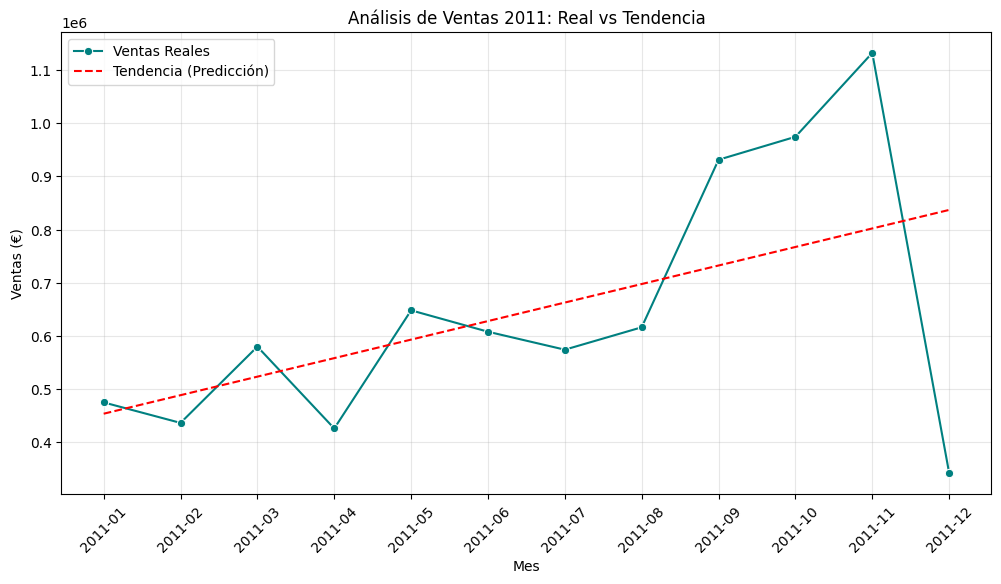

In [8]:
plt.figure(figsize=(12, 6))

# Dibujar las ventas reales
sns.lineplot(x=monthly_sales.index, y=y, marker='o', color='teal', label='Ventas Reales')

# Dibujar la línea de predicción (Tendencia)
plt.plot(monthly_sales.index, prediccion, color='red', linestyle='--', label='Tendencia (Predicción)')

# Configuración visual
plt.title('Análisis de Ventas 2011: Real vs Tendencia')
plt.xticks(rotation=45)
plt.xlabel('Mes')
plt.ylabel('Ventas (€)')
plt.legend() # Muestra la leyenda para identificar cada línea
plt.grid(True, alpha=0.3)

plt.show()

## Cálculo Automático de Crecimiento

In [9]:
# valor del primer y último mes del conjunto agrupado
ventas_iniciales = monthly_sales.iloc[0]
ventas_finales = monthly_sales.iloc[-1]

# fórmula: ((Final - Inicial) / Inicial) * 100
crecimiento_total = ((ventas_finales - ventas_iniciales) / ventas_iniciales) * 100

# resultado 

print("Resumen Ejecutivo:")
print(f"Ventas Iniciales: {ventas_iniciales:.2f} €")
print(f"Ventas Finales: {ventas_finales:.2f} €")
print(f"Porcentaje de Crecimiento Total: {crecimiento_total:.2f}%")

Resumen Ejecutivo:
Ventas Iniciales: 475074.38 €
Ventas Finales: 342506.38 €
Porcentaje de Crecimiento Total: -27.90%
